In [1]:
!pip install seaborn pandas numpy

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import seaborn as sns
import pandas as pd
import numpy as np

In [3]:
# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [5]:
# To display all column names
df.columns



Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='object')

In [6]:
# To check the number of rows ad columns
df.shape

(6433, 14)

In [7]:
# To check the information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6389 non-null   object        
 10  pickup_zone      6407 non-null   object        
 11  dropoff_zone     6388 non-null   object        
 12  pickup_borough   6407 non-null   object        
 13  dropoff_borough  6388 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

2 . Handling Missig values

In [8]:
# To check the missing values in each column
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [9]:
# To calculate the total missing values
df.isnull().sum().sum()

np.int64(186)

In [10]:
# To identify columns cotainingg missing values

missing_columns = df.columns[df.isnull().any()]

print("Columns containing missing values:")

print(missing_columns)

Columns containing missing values:
Index(['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')


In [11]:
# To identify numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numerical_columns)


#  To identify categorical columns

categorical_columns = df.select_dtypes(include="object").columns

print("Categorical Columns:")
print(categorical_columns)

Numerical Columns:
Index(['passengers', 'distance', 'fare', 'tip', 'tolls', 'total'], dtype='object')
Categorical Columns:
Index(['color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough',
       'dropoff_borough'],
      dtype='object')


In [12]:
# Handling numerical values using median
# For columns such as passengers, distance, fare, tip, tolls and total, median imputation can be useful
# Median is less affected by extremely high or low values compared to mean. Taxi fares and tips can contain outliers, so median is a reasonable choice
# Fill missing numerical values using median

for col in numerical_columns:

    df[col] = df[col].fillna(df[col].median())

print("Numerical missing values handled successfully!")

Numerical missing values handled successfully!


In [13]:
# Handle categorical missing values using mode
# Categorical columns include: colour, payment,pickup_borough,dropoff_borough

# To identify categorical columns

categorical_columns = df.select_dtypes(include=["object", "category"]).columns

# To Fill missing categorical values using mode

for col in categorical_columns:

    if df[col].isnull().sum() > 0:

        df[col] = df[col].fillna(df[col].mode()[0])

print("Categorical missing values handled successfully!")

Categorical missing values handled successfully!


In [14]:
# Handle critical missing values by removing rows
# Some columns may contain information that cannot reasonably be impute
# - Pickup time ,Drop-off time
#These are important for understanding when the journey started and ended. Instead of inventing timestamps, we can remove rows where these values are missing

# Remove rows with missing pickup and dropoff timestamps

df.dropna(subset=["pickup", "dropoff"], inplace=True)

print("Rows with missing critical timestamps removed!")

Rows with missing critical timestamps removed!


In [15]:
# Check missing values after cleaning

print("Missing values after cleaning:")

print(df.isnull().sum())

Missing values after cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [18]:
df_original = sns.load_dataset("taxis")

In [19]:
# Compare before and after cleaning of dataset

print("Original Dataset Shape:", df_original.shape)

print("Cleaned Dataset Shape:", df.shape)

Original Dataset Shape: (6433, 14)
Cleaned Dataset Shape: (6433, 14)


In [20]:
# Display first five rows of cleaned dataset

df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [21]:
# To display the complete dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6433 non-null   object        
 10  pickup_zone      6433 non-null   object        
 11  dropoff_zone     6433 non-null   object        
 12  pickup_borough   6433 non-null   object        
 13  dropoff_borough  6433 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

3. Visualising using matplotlib/pandas plot

In [22]:
# Import required libraries

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [23]:
# Set a common chart style:

sns.set_style("whitegrid")

In [24]:
# Check and convert the pickup column into datetime

# Convert pickup column into datetime format

df["pickup"] = pd.to_datetime(df["pickup"])

# Check the data type

print(df["pickup"].dtype)

datetime64[ns]


A. Line Chart  

Plot a line chart to visualize the fare over time, using the pickup timestamp as the 
x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime 
format before plotting. 

In [29]:
df["pickup"] = pd.to_datetime(df["pickup"])

In [26]:
# To sort the pickup timestamps

df_sorted = df.sort_values(by="pickup")

In [28]:
# To calculate daily average fare

daily_fare = df_sorted.set_index("pickup")["fare"].resample("D").mean()

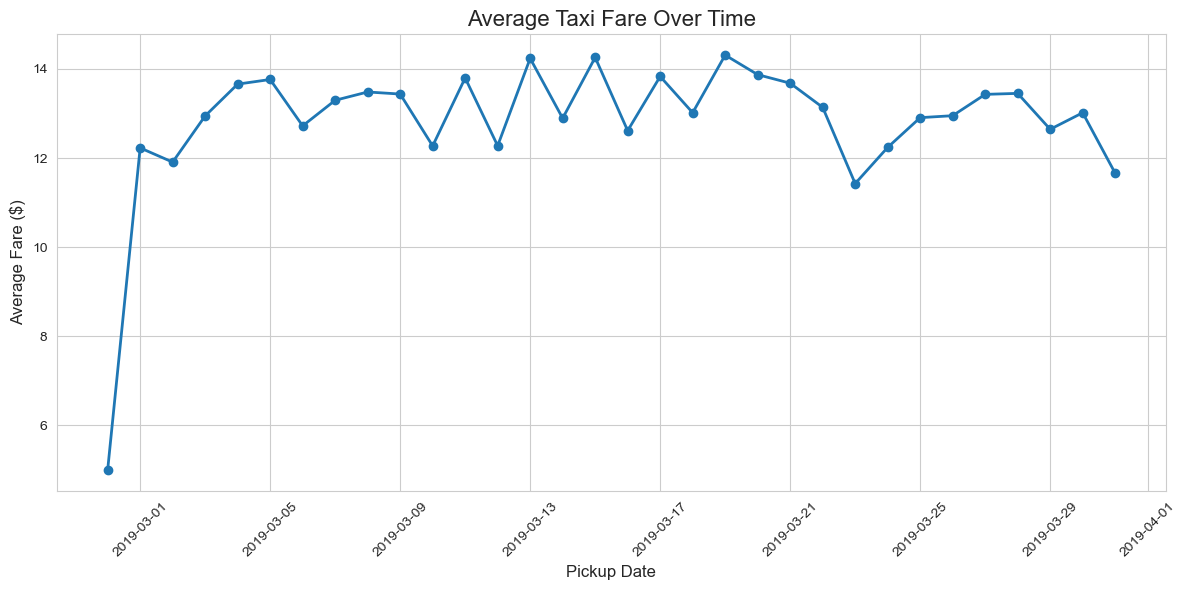

In [30]:
plt.figure(figsize=(12, 6))

plt.plot(daily_fare.index, daily_fare.values,
         marker="o", linewidth=2)

plt.title("Average Taxi Fare Over Time", fontsize=16)

plt.xlabel("Pickup Date", fontsize=12)

plt.ylabel("Average Fare ($)", fontsize=12)

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()

B. Bar Chart  
Create a bar chart to show the total fare for each pickup_borough. Group the data 
by pickup_borough and sum the fare for each group. 

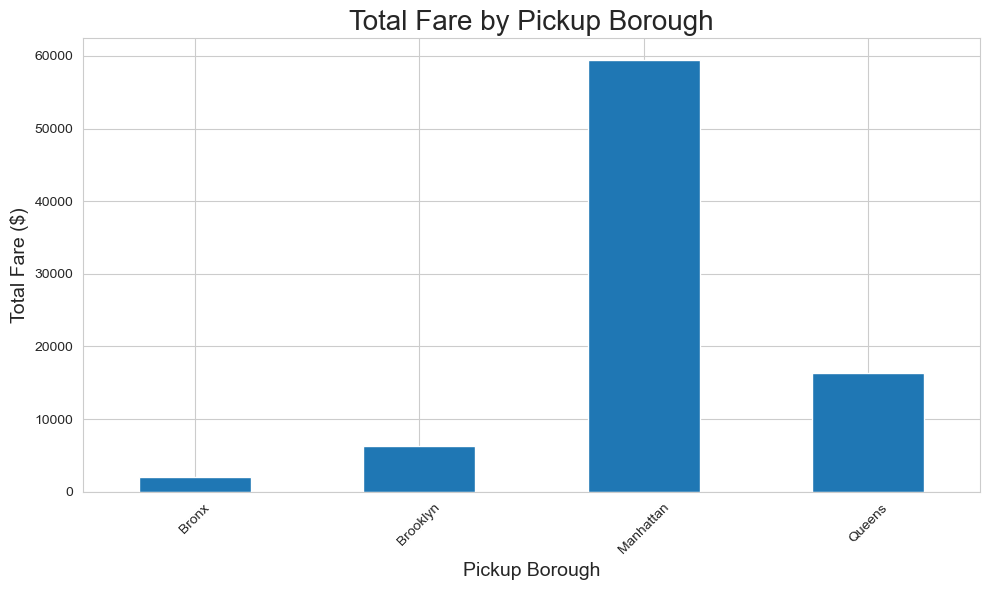

In [36]:
# Group data by pickup borough and calculate total fare

borough_fare = df.groupby("pickup_borough")["fare"].sum()

# Create bar chart

plt.figure(figsize=(10, 6))

borough_fare.plot(kind="bar")

# Add title and labels

plt.title("Total Fare by Pickup Borough", fontsize=20)

plt.xlabel("Pickup Borough", fontsize=14)

plt.ylabel("Total Fare ($)", fontsize=14)

# Rotate x-axis labels

plt.xticks(rotation=45)

# Display chart

plt.tight_layout()

plt.show()

C. Pie Chart  
Plot a pie chart showing the distribution of trips based on the payment method (credit 
card, cash, etc.). Each slice should represent the count of trips for a specific payment 
method.



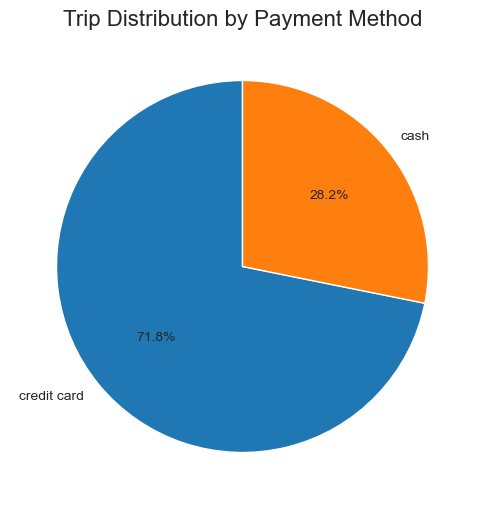

In [38]:
# Count trips by payment method

payment_counts = df["payment"].value_counts()

# Create pie chart

plt.figure(figsize=(6, 8))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

# Add title

plt.title("Trip Distribution by Payment Method", fontsize=16)

# Display chart

plt.show()

D. Histogram  
Create a histogram to visualize the distribution of distance. Customize the number of 
bins for better granularity and ensure the plot is easy to interpret.

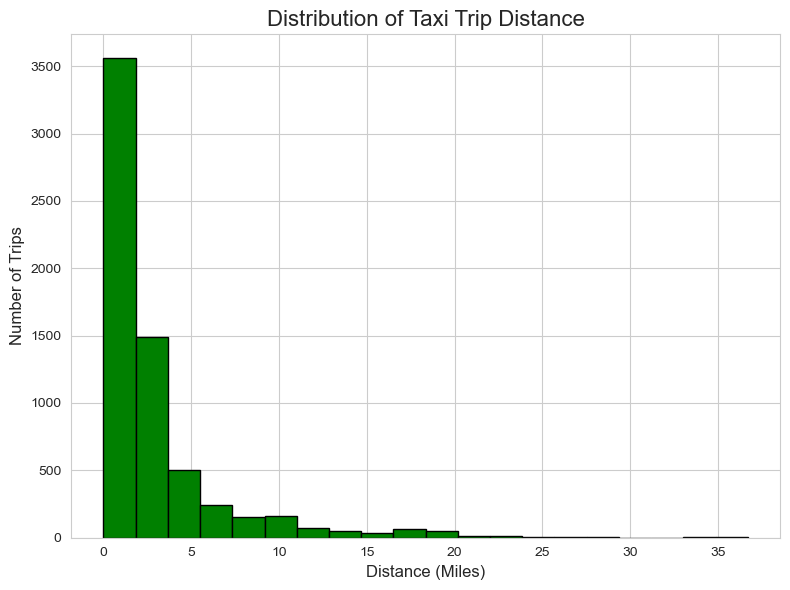

In [41]:
# Create histogram

plt.figure(figsize=(8, 6))

plt.hist(
    df["distance"].dropna(),
    bins=20,
    color="green",
    edgecolor="black"
)

# Add title and labels

plt.title("Distribution of Taxi Trip Distance", fontsize=16)

plt.xlabel("Distance (Miles)", fontsize=12)

plt.ylabel("Number of Trips", fontsize=12)

# Display chart

plt.tight_layout()

plt.show()

E. Box Plot  
Plot a box plot to visualize the distribution of tip amounts for each pickup_borough. 
Use pickup_borough as the categorical axis and tip as the numeric axis. 

<Figure size 800x600 with 0 Axes>

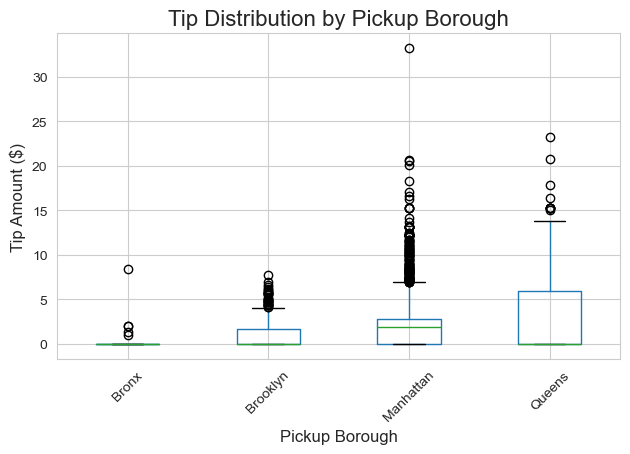

In [42]:
# Create box plot

plt.figure(figsize=(8, 6))

df.boxplot(
    column="tip",
    by="pickup_borough",
    grid=True
)

# Add title and labels

plt.title("Tip Distribution by Pickup Borough", fontsize=16)

plt.suptitle("")

plt.xlabel("Pickup Borough", fontsize=12)

plt.ylabel("Tip Amount ($)", fontsize=12)

# Display chart

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

Visualisig using seaborn

In [43]:
# Import libraries

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Set visualization style

sns.set_style("whitegrid")

A. Count Plot  
Create a count plot to visualize the number of trips in each pickup_borough. The 
x-axis should represent the boroughs, and the y-axis should show the count of trips

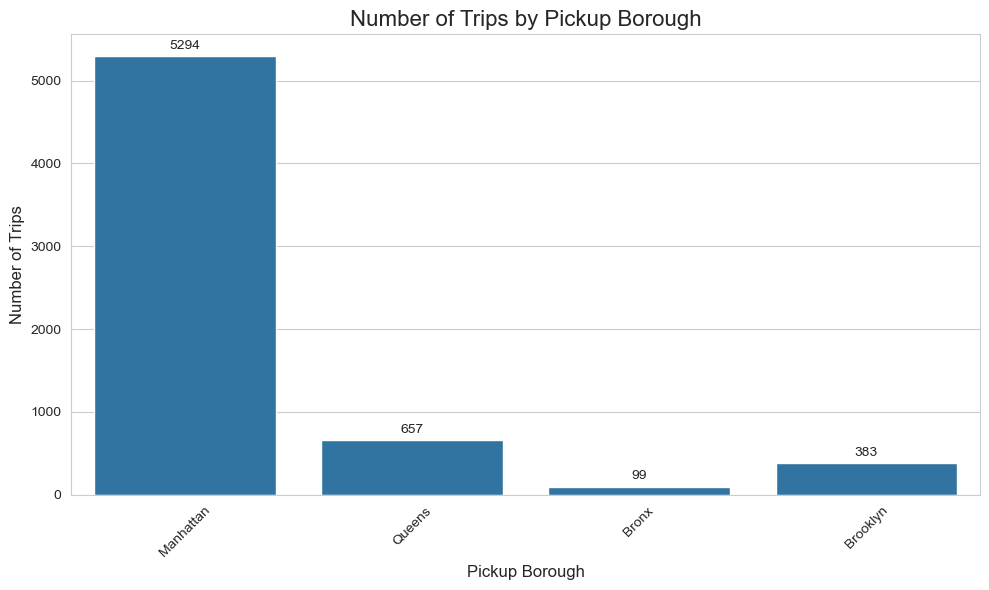

In [47]:
# Set chart size

plt.figure(figsize=(10, 6))

# Create count plot

ax = sns.countplot(data=df, x="pickup_borough")

# Add title

plt.title("Number of Trips by Pickup Borough", fontsize=16)

# Add X-axis and Y-axis labels

plt.xlabel("Pickup Borough", fontsize=12)

plt.ylabel("Number of Trips", fontsize=12)

# Display Y-axis tick values

plt.yticks(fontsize=10)

# Display count values above each bar

for container in ax.containers:
    ax.bar_label(container, padding=3)

# Rotate X-axis labels

plt.xticks(rotation=45)

# Adjust layout

plt.tight_layout()

# Display chart

plt.show()

Count Plot – Trips by Pickup Borough
The count plot shows the number of taxi trips originating from each pickup borough.
It helps identify which borough has the highest and lowest number of taxi pickups.

B.  Scatter Plot  
Plot a scatter plot to show the relationship between distance and fare. Use 
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the 
points based on the pickup_borough to differentiate the trips by their respective 
boroughs.

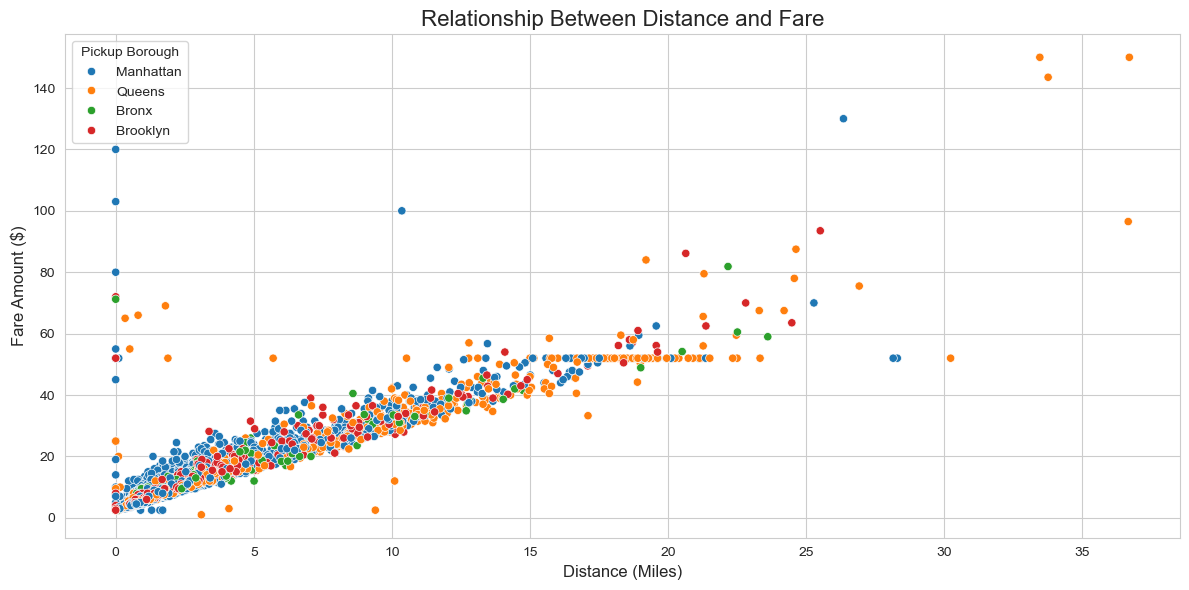

In [48]:
# Create scatter plot

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough"
)

# Add title and labels

plt.title("Relationship Between Distance and Fare", fontsize=16)

plt.xlabel("Distance (Miles)", fontsize=12)

plt.ylabel("Fare Amount ($)", fontsize=12)

plt.legend(title="Pickup Borough")

plt.tight_layout()

plt.show()

Scatter Plot – Distance vs Fare with Borough Colors.
The scatter plot shows the relationship between taxi distance and fare amount.
It generally indicates that fares increase as trip distance increases. Different colors represent different pickup boroughs.

C . Heatmap  
Plot a heatmap to visualize the correlation between numerical variables such as 
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the 
relationships.  

In [50]:
# Select numerical columns

numerical_data = df[["distance", "fare", "tip", "tolls", "total"]]

# Calculate correlation matrix

correlation_matrix = numerical_data.corr()

# Display correlation matrix

print(correlation_matrix)

          distance      fare       tip     tolls     total
distance  1.000000  0.920108  0.452589  0.635267  0.904676
fare      0.920108  1.000000  0.488612  0.609307  0.974358
tip       0.452589  0.488612  1.000000  0.413619  0.646186
tolls     0.635267  0.609307  0.413619  1.000000  0.683142
total     0.904676  0.974358  0.646186  0.683142  1.000000


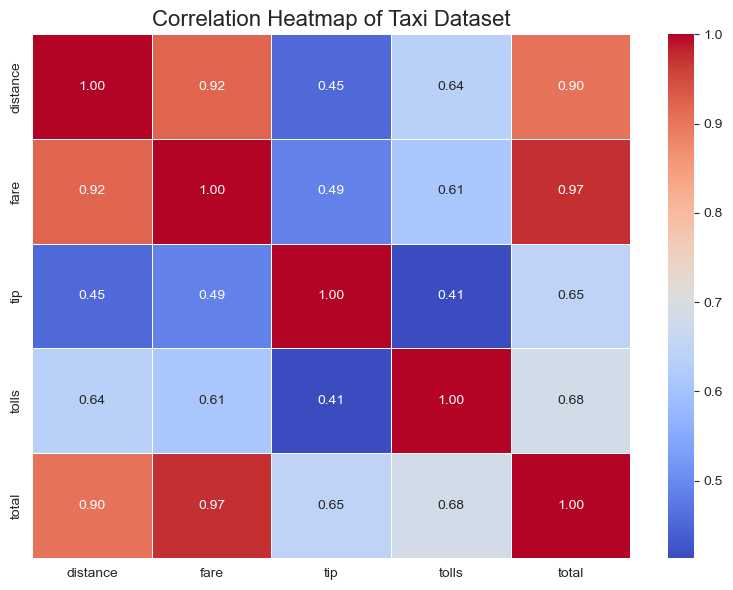

In [52]:
# Create heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

# Add title

plt.title("Correlation Heatmap of Taxi Dataset", fontsize=16)

plt.tight_layout()

plt.show()

Heatmap – Numerical Correlation.
The heatmap displays the correlation between distance, fare, tip, tolls and total. It helps identify positive and negative relationships between numerical variables. Stronger correlations are represented by more intense colors.

D .  Pair Plot  
Create a pair plot to visualize the pairwise relationships between distance, fare, tip, 
and total. Color the data points according to the pickup_zone method to compare 
how different zones affect these variables. 

In [53]:
# Select required columns

pair_data = df[["distance", "fare", "tip", "total", "pickup_zone"]].dropna()

# Find the five most common pickup zones

top_zones = pair_data["pickup_zone"].value_counts().head(5).index

# Filter data for these five zones

pair_data = pair_data[pair_data["pickup_zone"].isin(top_zones)]

# Take a sample to make plotting faster

pair_data = pair_data.sample(
    n=min(500, len(pair_data)),
    random_state=42
)

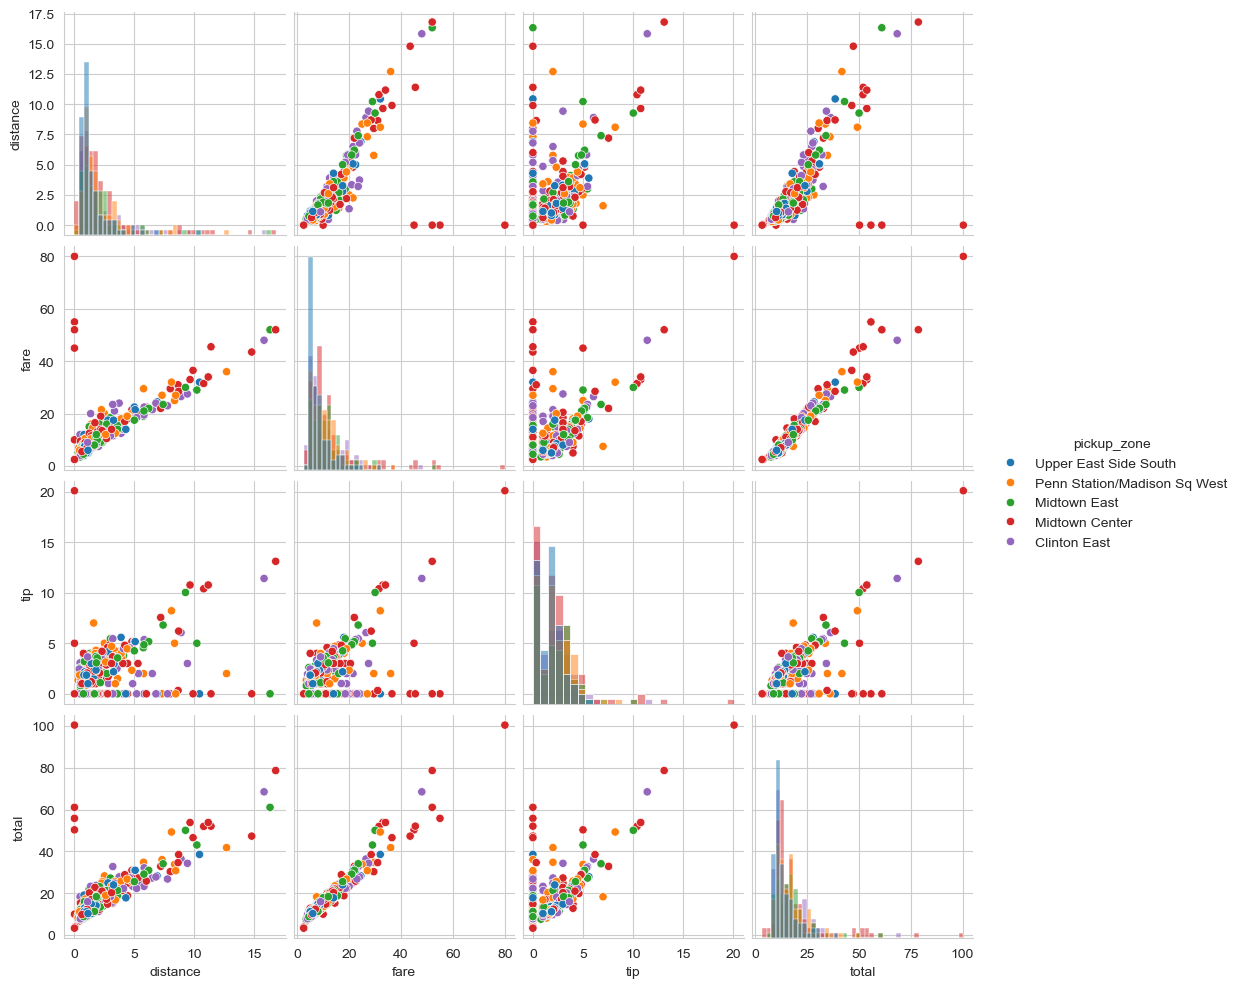

In [55]:
# Create pair plot

sns.pairplot(
    data=pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)

# Display chart

plt.show()

Pair Plot – Distance, Fare, Tip and Total with Pickup Zone.
The pair plot illustrates the pairwise relationships between distance, fare, tip and total. Different colors represent pickup zones, helping compare variable distributions and relationships across different zones

E. Violin Plot  
Plot a violin plot to show the distribution of fare for each payment method. Use the 
payment method as the categorical axis and fare as the numeric axis to visualize its 
distribution. 

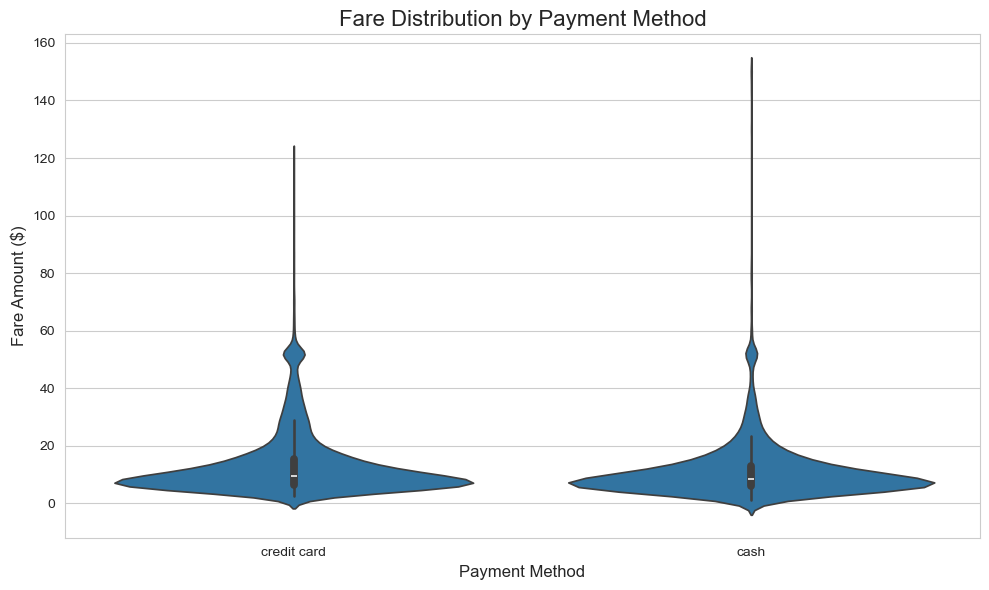

In [56]:
# Objective: Visualize the distribution of taxi fares for different payment methods.
#  X-axis: Payment method.
#  Y-axis: Fare amount.

# Create violin plot

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df.dropna(subset=["payment", "fare"]),
    x="payment",
    y="fare"
)

# Add title and labels

plt.title("Fare Distribution by Payment Method", fontsize=16)

plt.xlabel("Payment Method", fontsize=12)

plt.ylabel("Fare Amount ($)", fontsize=12)

plt.tight_layout()

plt.show()

Violin Plot – Fare by Payment Method.
The violin plot shows the distribution of taxi fares for different payment methods, such as cash and credit card. It helps compare fare distributions, identify common fare ranges and observe variations between payment methods